In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib as mpl
import pandas as pd
import pickle
from collections import Counter
import scanpy as sc
import anndata as ad
import os
import random
import STalign
import torch
import plotly
import requests

/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/py

In [2]:
visium_data_sub_selected = sc.read_h5ad('./DBiT_imputation-CellViT-Xenium-FFPE-BreastCancer-Xenium_genes_predict_annotated_withHE_full.h5ad')

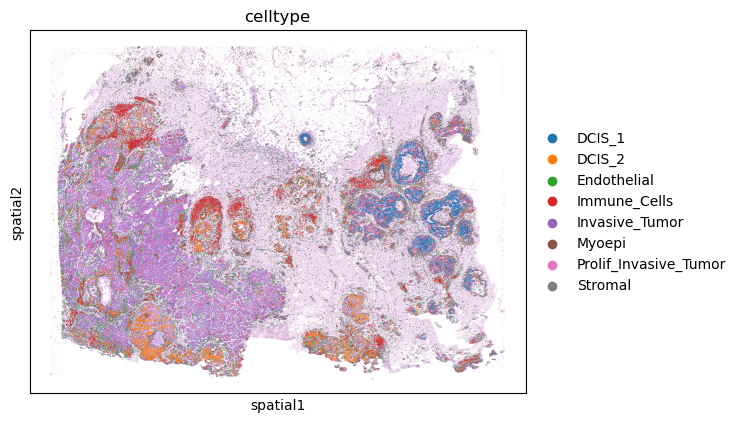

In [21]:
sc.pl.spatial(visium_data_sub_selected, color='celltype', size=1.8, img_key='hires', alpha_img=0.6)

In [14]:
he_img = visium_data_sub_selected.uns['spatial']['Xenium_Visium_FFPE_BreastCancer']['images']['hires']

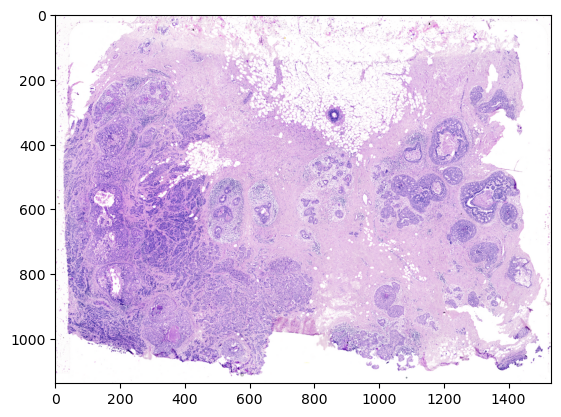

In [15]:
plt.imshow(he_img)

In [16]:
from PIL import Image, ImageOps
pil_he_img = Image.fromarray(he_img)
invert_he_img = ImageOps.invert(pil_he_img)
gray_he_img = invert_he_img.convert('LA')
gray_he_img_array = np.array(gray_he_img)
gray_he_img_final = np.stack((gray_he_img_array[:, :, 0],)*3, axis=-1)

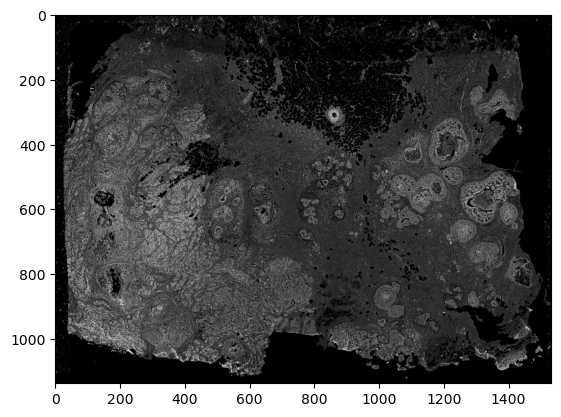

In [17]:
plt.imshow(gray_he_img_final)

In [26]:
visium_data_sub_selected.uns['spatial']['Xenium_Visium_FFPE_BreastCancer']['images']['invert'] = gray_he_img_final
visium_data_sub_selected.uns['spatial']['Xenium_Visium_FFPE_BreastCancer']["scalefactors"]['tissue_invert_scalef'] = visium_data_sub_selected.uns['spatial']['Xenium_Visium_FFPE_BreastCancer']["scalefactors"]['tissue_hires_scalef']

In [27]:
visium_data_sub_selected.uns['celltype_colors']

['#1f77b4',
 '#ff7f0e',
 '#2ca02c',
 '#d62728',
 '#9467bd',
 '#8c564b',
 '#e377c2',
 '#7f7f7f']

In [31]:
color_list = ['#1f77b4', '#abddde', '#d7ef9b', '#2ca02c', '#cc66ff', '#ffff0a', '#b487b7',
       '#ff7f0e']
visium_data_sub_selected.uns['celltype_colors'] = color_list
visium_data_sub_selected.uns['celltype2_colors'] = color_list

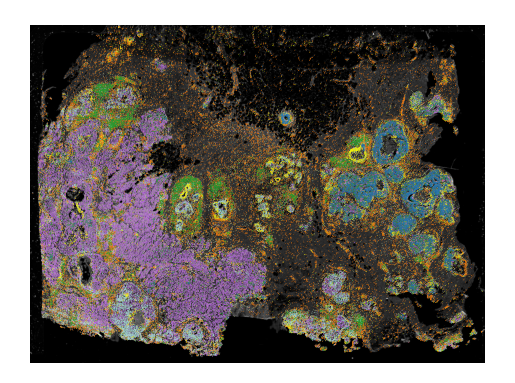

In [33]:
fig = sc.pl.spatial(visium_data_sub_selected, color='celltype', size=1.8, img_key='invert', alpha_img=1.0, legend_loc=None,frameon=False, title='', show=False, return_fig=True)
fig.savefig(f'BreastCancer_our_annotation2_HE_noframe_full.pdf', bbox_inches='tight', pad_inches=0)

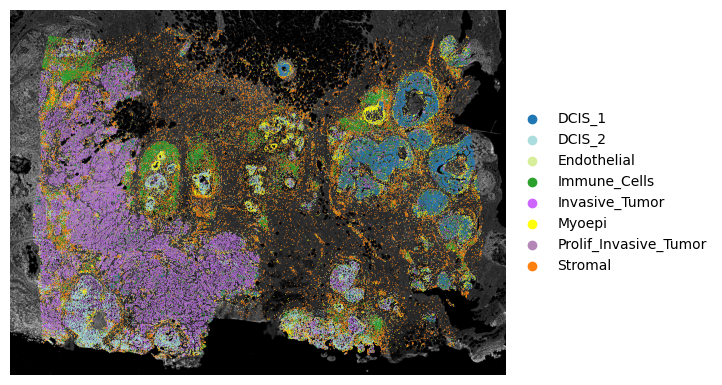

In [12]:
fig = sc.pl.spatial(visium_data_sub_selected, color='celltype', size=1.8, img_key='invert', alpha_img=1.0, frameon=False, title='', show=False, return_fig=True)
fig.savefig(f'BreastCancer_our_annotation2_HE.pdf', bbox_inches='tight', pad_inches=0)

In [34]:
visium_data_sub_selected

AnnData object with n_obs × n_vars = 169095 × 313
    obs: 'x', 'y', 'section_id', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'sample_id', 'leiden_0.1', 'leiden_0.2', 'celltype', 'celltype2'
    var: 'mean', 'std'
    uns: 'leiden_0.1', 'leiden_0.1_colors', 'leiden_0.2', 'leiden_0.6_colors', 'neighbors', 'spatial', 'umap', 'celltype2_colors', 'log1p', 'celltype_colors'
    obsm: 'X_pca', 'X_umap', 'spatial', 'spatial_visium', 'spatial_HE'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [36]:
CEACAM6 = visium_data_sub_selected[:, 'CEACAM6'].X.toarray()[:, 0]
CEACAM6[visium_data_sub_selected[:, 'CEACAM6'].X.toarray()[:, 0] < 1.2] = 0
visium_data_sub_selected.obs['CEACAM6_1'] = CEACAM6

In [37]:
ACTA2 = visium_data_sub_selected[:, 'ACTA2'].X.toarray()[:, 0]
ACTA2[visium_data_sub_selected[:, 'ACTA2'].X.toarray()[:, 0] < 0.6] = 0
visium_data_sub_selected.obs['ACTA2_1'] = ACTA2

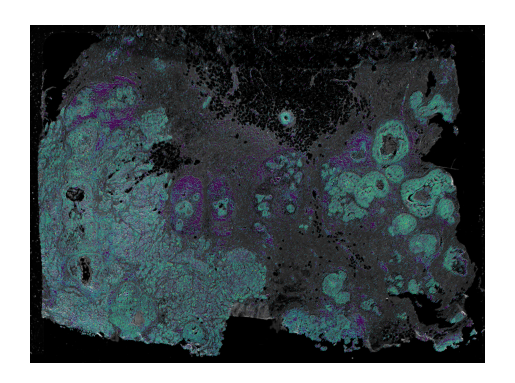

In [43]:
gene = 'TACSTD2'#'ERBB2'#'CEACAM6_1'#'CEACAM6'#'ACTA2_1'#'IL7R'#
fig = sc.pl.spatial(visium_data_sub_selected, color=gene, size=1.5, img_key='invert', alpha_img=1.0, legend_loc=None,frameon=False, colorbar_loc=None, title='', show=False, return_fig=True)
fig.savefig(f'BreastCancer_our_{gene}_HE_noframe_full.pdf', bbox_inches='tight', pad_inches=0)

In [44]:
xenium_data_sub_selected = sc.read_h5ad('./DBiT_imputation-CellViT-Xenium-FFPE-BreastCancer-original_annotated_withHE.h5ad')

In [45]:
xenium_data_sub_selected.obsm['spatial'] = xenium_data_sub_selected.obsm['spatial_HE'][:, [1,0]]
xenium_data_sub_selected.uns['spatial'] = visium_data_sub_selected.uns['spatial']

In [46]:
xenium_data_sub_selected.uns['spatial']['Xenium_Visium_FFPE_BreastCancer']['images']['invert'] = gray_he_img_final
xenium_data_sub_selected.uns['spatial']['Xenium_Visium_FFPE_BreastCancer']["scalefactors"]['tissue_invert_scalef'] = xenium_data_sub_selected.uns['spatial']['Xenium_Visium_FFPE_BreastCancer']["scalefactors"]['tissue_hires_scalef']

In [47]:
color_list = ['#1f77b4', '#abddde', '#d7ef9b', '#2ca02c', '#cc66ff', '#ffff0a', '#b487b7',
       '#ff7f0e', '#bcbd22']
xenium_data_sub_selected.uns['celltype_colors'] = color_list

In [50]:
height, width, _ = gray_he_img_final.shape

In [62]:
hires_scale = xenium_data_sub_selected.uns['spatial']['Xenium_Visium_FFPE_BreastCancer']["scalefactors"]['tissue_invert_scalef']

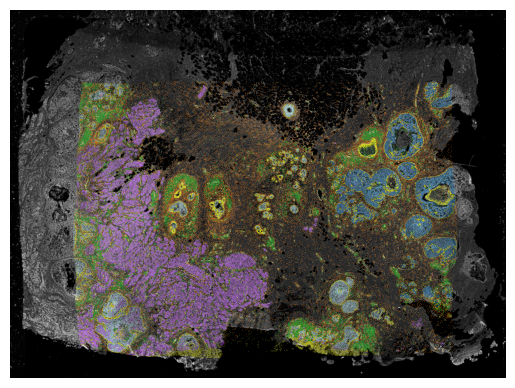

In [64]:
fig = sc.pl.spatial(xenium_data_sub_selected, color='celltype', size=1.3, img_key='invert', alpha_img=1.0, legend_loc=None,frameon=False, title='', return_fig=True, crop_coord=[0, width/hires_scale, 0, height/hires_scale], show=True)
fig.savefig(f'BreastCancer_Xenium_annotation_HE_noframe_full.pdf', bbox_inches='tight', pad_inches=0)

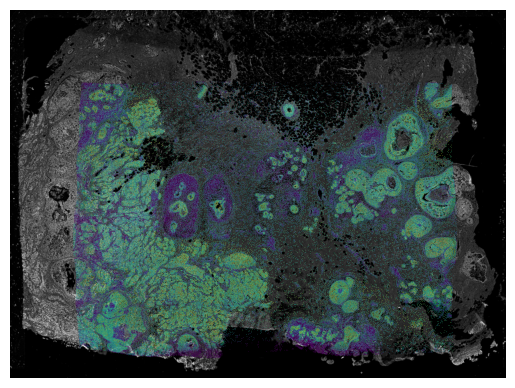

In [69]:
gene = 'ERBB2'#'CEACAM6'#'ACTA2'#'IL7R'#'TACSTD2'#
fig = sc.pl.spatial(xenium_data_sub_selected, color=gene, size=1.5, img_key='invert', alpha_img=1.0, legend_loc=None, colorbar_loc=None, frameon=False, title='', show=False, return_fig=True, crop_coord=[0, width/hires_scale, 0, height/hires_scale])
fig.savefig(f'BreastCancer_Xenium_{gene}_HE_noframe_full.pdf', bbox_inches='tight', pad_inches=0)